# Which items go together on twelve Instamart carts, and what does "together" mean?

**Week 4, Wednesday, chapter 1 of 3.** Swiggy Instamart, Pune: the cart page shows a strip
of three suggested items under the cart. On Monday 7 September 2026 the strip stopped showing a
curated list and started showing the items most often found in the same cart. Toned milk
sits in 71 percent of Pune carts, so it now appears beside nearly everything,
and the strip's click-through (clicks over impressions, an impression being one showing of
one slot) fell from 6.1 percent in the three weeks before to
3.8 percent in the three weeks after. The ask, due Friday: rank the pairs the
strip should show, explain the fall, and put a rupee value on a slot. Illustrative case: the company is real, the situation and the data are synthetic, built for this class.

**Who needs the answer.** The category manager, who decides which products are promoted,
and the growth lead, who owns the strip's clicks and orders and must explain the fall at
Friday's review, the weekly meeting where both defend their numbers. A strip filled on the
wrong count wastes the three most-clicked spaces on the cart page.

**The questions on the way.** How often do two items turn up in the same cart? How
reliably does one bring the other? Do they turn up together more than chance would put
them there? What can twelve carts not tell us?

In [1]:
def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)
    assert ok, name
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
import pandas as pd
print("ready: pandas", pd.__version__)

ready: pandas 3.0.5


## Which sentence about ten tea-stall orders is wrong?

A tea stall keeps ten receipts (invented for this chapter). Chai is on 6 of them, biscuit
on 4, and both on 3. A pair has three counts worth knowing. **Support** is how often both
turn up: carts with both, over all carts. **Confidence** from A to B shrinks the world to
the orders that hold A and asks how many of those also hold B. **Lift** compares what was
seen with what chance would give: if chai and biscuit ignored each other, 60 percent of
the 4 biscuit orders, or 2.4, would also hold chai.

**Predict before you run.** Which sentence is wrong?

a) Support for the pair is 3 of 10, or 0.30.
b) Confidence from chai to biscuit is 3 of 6, or 0.50.
c) Lift is 1.25, and it reads the same from biscuit to chai.
d) Lift of 1.25 means chai makes a customer buy 25 percent more biscuits.

In [2]:
orders, chai, biscuit, both = 10, 6, 4, 3            # invented counts
support = both / orders
conf_chai_biscuit = both / chai
conf_biscuit_chai = both / biscuit
expected = orders * (chai / orders) * (biscuit / orders)   # if the two ignored each other
lift = both / expected
print(f"support {support:.2f}, confidence chai to biscuit {conf_chai_biscuit:.2f}, "
      f"biscuit to chai {conf_biscuit_chai:.2f}")
print(f"expected together {expected:.1f}, seen {both}, lift {lift:.2f}")
check("lift reads the same both ways", abs(lift - conf_biscuit_chai / (chai / orders)) < 1e-9)
check("lift is seen over expected", abs(lift - 1.25) < 1e-9)

support 0.30, confidence chai to biscuit 0.50, biscuit to chai 0.75
expected together 2.4, seen 3, lift 1.25
PASS lift reads the same both ways
PASS lift is seen over expected


**What happened.** The wrong sentence is d. Lift is a ratio of counts: the pair turns up
25 percent more often than chance would put it there, and nothing in ten receipts says
why. Lift is also a confidence over the partner's own share, which is why it reads the same
from both sides: chai to biscuit 0.50 / 0.40 = 1.25, and biscuit to
chai 0.75 / 0.60 = 1.25. Now add a carry bag, which goes into 9 of the 10 orders and into 3 of the 4 biscuit
orders. Confidence from biscuit to bag is 0.75, which sounds like a bundle,
yet the bag is in 9 of 10 orders anyway, so lift, the
confidence over the bag's own share, is 0.75 / 0.90 = 0.83: biscuit orders hold a bag slightly less often than orders
in general. An item that is everywhere earns high confidence toward everything.

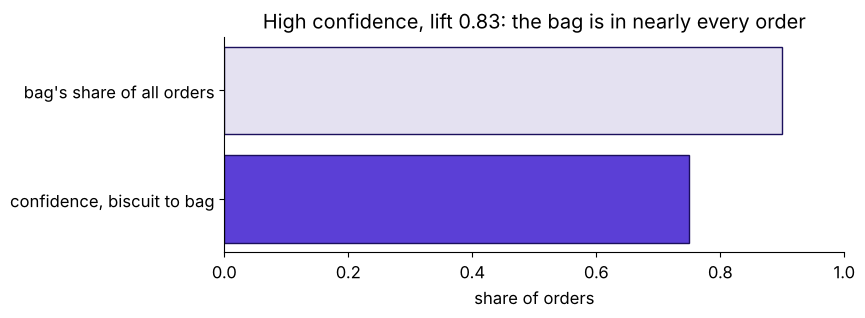

PASS the popular bag earns lift below one


In [3]:
bag, biscuit_with_bag = 9, 3                         # invented counts
conf_biscuit_bag = biscuit_with_bag / biscuit
lift_bag = conf_biscuit_bag / (bag / orders)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(["confidence, biscuit to bag", "bag's share of all orders"], [conf_biscuit_bag, bag / orders],
        color=["#5B3FD6", "#E4E1F1"], edgecolor="#1A0F5C")
ax.set_xlim(0, 1)
ax.set_xlabel("share of orders")
ax.set_title(f"High confidence, lift {lift_bag:.2f}: the bag is in nearly every order")
plt.show()
check("the popular bag earns lift below one", lift_bag < 1)

## What do twelve carts from the case hold?

These are twelve of the 40,000 Pune carts, printed as cards on each table. Each row is a
cart and each column an item: 1 if the cart holds it. Count by hand first; the code below
only confirms the count.

C000098 bananas, bread, coriander, eggs, onions, potatoes, toned milk
C003216 bananas, bread, curd, eggs, toned milk
C006334 bread, curd, onions, paneer, toned milk
C009452 bread, eggs, tomatoes, toned milk
C012570 chips, cold drink, eggs, onions, toned milk
C015688 chips, cold drink, coriander, toned milk
C018806 bananas, onions, potatoes, toned milk
C022633 coriander, paneer, tomatoes, toned milk
C026803 chips, coriander, onions, potatoes
C030743 bananas, cold drink, curd, tomatoes
C033861 chocolate sauce, eggs, ice cream
C036979 curd, onions


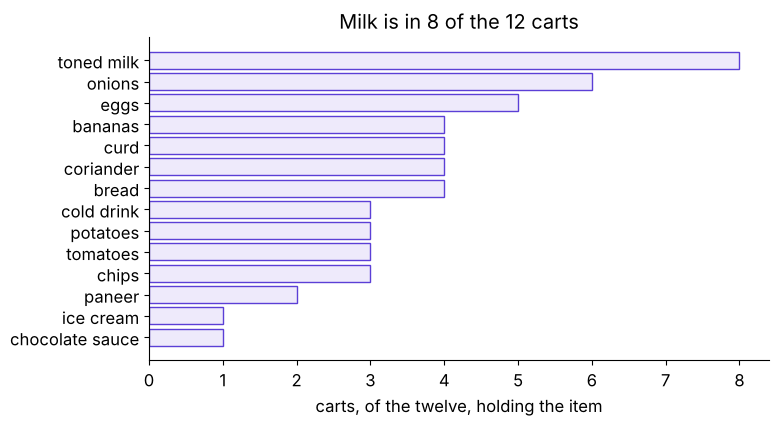

PASS twelve carts


In [4]:
twelve = pd.read_csv("../data/C2_W04_D03_twelve_rows_STUDENT.csv").set_index("cart_id")
for cart_id, row in twelve.iterrows():
    print(cart_id, ", ".join(row.index[row == 1]))
held = twelve.sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(held.index, held.values, color="#EEEAFB", edgecolor="#5B3FD6")
ax.set_xlabel("carts, of the twelve, holding the item")
ax.set_title("Milk is in 8 of the 12 carts")
plt.show()
check("twelve carts", len(twelve) == 12)

## How reliably does bread bring milk on the twelve carts?

Bread is in 4 carts and milk in 8.

**Predict before you run.** What is the confidence from bread to milk?

a) 0.33
b) 0.50
c) 0.75
d) 1.00

In [5]:
n = len(twelve)
bread, milk = twelve["bread"] == 1, twelve["toned milk"] == 1
both = (bread & milk).sum()
conf = both / bread.sum()
expected = n * (bread.sum() / n) * (milk.sum() / n)
lift = both / expected
print(f"bread {bread.sum()}, milk {milk.sum()}, both {both}")
print(f"support {both / n:.2f}, confidence bread to milk {conf:.2f}, milk to bread {both / milk.sum():.2f}")
print(f"expected together {expected:.2f}, seen {both}, lift {lift:.2f}")
check("every bread cart holds milk", conf == 1.0)
check("lift is 1.50 on the twelve", round(lift, 2) == 1.50)

bread 4, milk 8, both 4
support 0.33, confidence bread to milk 1.00, milk to bread 0.50
expected together 2.67, seen 4, lift 1.50
PASS every bread cart holds milk
PASS lift is 1.50 on the twelve


**What happened.** The answer is d: all four bread carts hold milk, so confidence reads
1.00. That is the trap of this chapter. A hurried analyst reads
1.00 as "every bread buyer wants milk, so put milk in the bread cart's strip". The check
is the count the confidence never looked at: milk was already in 8 of 12 carts, so chance
alone puts it in about 2.67 of the four bread carts, and lift is 4 / 2.67 =
1.50. Four carts are too few to say more; chapter 2 runs the
same count on 40,000.

In [6]:
def three_counts(a, b):
    has_a, has_b = twelve[a] == 1, twelve[b] == 1
    both = (has_a & has_b).sum()
    return both, has_a.sum(), has_b.sum(), both / n, both / has_a.sum(), both * n / (has_a.sum() * has_b.sum())

for a, b in [("chips", "cold drink"), ("ice cream", "chocolate sauce")]:
    both, na, nb, sup, conf, lift = three_counts(a, b)
    print(f"{a} and {b}: {na} and {nb} carts, both {both}, support {sup:.2f}, "
          f"confidence {conf:.2f}, lift {lift:.2f}")
check("chips and cold drink: lift 2.67", round(three_counts("chips", "cold drink")[5], 2) == 2.67)
check("ice cream and chocolate sauce: one cart, lift 12", three_counts("ice cream", "chocolate sauce")[0] == 1)

chips and cold drink: 3 and 3 carts, both 2, support 0.17, confidence 0.67, lift 2.67
ice cream and chocolate sauce: 1 and 1 carts, both 1, support 0.08, confidence 1.00, lift 12.00
PASS chips and cold drink: lift 2.67
PASS ice cream and chocolate sauce: one cart, lift 12


## Which pair beat chance on the twelve, and which number should nobody act on?

Chips and cold drink sit in 3 carts each and together in 2, where chance gives 0.75: lift
2.67. Ice cream and chocolate sauce share one cart, and one cart makes a lift of 12, a
number with nothing under it. The function above writes lift as both x n / (A x B), which
is seen over expected rearranged: for bread and milk, 4 / (12 x 4/12 x 8/12) is the same as
4 x 12 / (4 x 8), which is 1.50. The picture puts seen beside expected for the three pairs.

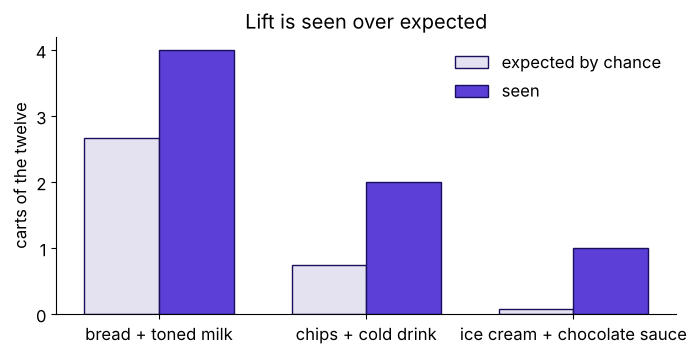

PASS every pair here was seen more often than chance


In [7]:
pairs = [("bread", "toned milk"), ("chips", "cold drink"), ("ice cream", "chocolate sauce")]
seen = [three_counts(a, b)[0] for a, b in pairs]
expect = [three_counts(a, b)[1] * three_counts(a, b)[2] / n for a, b in pairs]
fig, ax = plt.subplots(figsize=(8, 3.6))
x = range(len(pairs))
ax.bar([i - 0.18 for i in x], expect, 0.36, color="#E4E1F1", edgecolor="#1A0F5C", label="expected by chance")
ax.bar([i + 0.18 for i in x], seen, 0.36, color="#5B3FD6", edgecolor="#1A0F5C", label="seen")
ax.set_xticks(list(x), [f"{a} + {b}" for a, b in pairs])
ax.set_ylabel("carts of the twelve")
ax.legend(frameon=False)
ax.set_title("Lift is seen over expected")
plt.show()
check("every pair here was seen more often than chance", all(s > e for s, e in zip(seen, expect)))

## What did the twelve carts answer?

- **How often?** Support counts carts with both: bread and milk 4 of 12, chips and cold
  drink 2 of 12.
- **How reliably?** Confidence shrinks the world to the carts with A: bread to milk 4 of 4,
  1.00.
- **Against chance?** Lift divides seen by expected: bread and milk
  1.50, chips and cold drink 2.67, ice
  cream and chocolate sauce 12 on a single cart.
- **What can twelve carts not tell us?** Whether 1.50 is a real pull or four lucky carts.
  Chapter 2 counts all 40,000.

**In the interview.** "Support, confidence, lift: what does each answer?" The answer names
three questions: how often, how reliably, and against chance.